# Parallel Image Sharpening using OpenMP (2D Convolution)
**Course:** CSS311 – Parallel & Distributed Computing  
**Theme:** Image Processing | **Topic:** Image Sharpening using Convolution

---

### Parallel Decomposition Analysis
* **Sequential Portions:** Binary file stream I/O (raw `.bin` buffer loading and serialization), dynamic memory allocation via `std::vector`, and command-line argument validation execute sequentially.
* **Parallel Portions:** The 2D spatial convolution loop across image height (rows $r$) and width (columns $c$) contains strictly read-only neighbors with no loop-carried data dependencies, making it embarrassingly parallel.
* **Data Decomposition:** 1D domain decomposition along the vertical image dimension (image rows). Each OpenMP thread is assigned a contiguous chunk of rows using static scheduling (`schedule(static)`).
* **Synchronization & Safety:** The input pixel buffer is accessed in read-only mode. Each thread writes exclusively to disjoint, non-overlapping index locations in the output pixel array; therefore, no mutual exclusion (mutexes, critical sections, or atomic operations) is required.

---

### Mathematical Metrics Reference
* **Laplacian Sharpening Kernel:**
  $$\begin{bmatrix} 0 & -1 & 0 \\ -1 & 5 & -1 \\ 0 & -1 & 0 \end{bmatrix}$$

* **Speedup ($S_p$):**
  $$S_p = \frac{T_{\text{seq}}}{T_{\text{omp}}(p)}$$
  *(where $T_{\text{seq}}$ is the sequential baseline execution time, and $T_{\text{omp}}(p)$ is the OpenMP execution time on $p$ threads)*

* **Parallel Efficiency ($E_p$):**
  $$E_p = \frac{S_p}{p} = \frac{T_{\text{seq}}}{p \cdot T_{\text{omp}}(p)}$$

##Download Base Image and Prepare Binary Datasets

In [ ]:
import cv2
import numpy as np
import urllib.request
import os

# Download a detailed test image
image_url = "https://images.unsplash.com/photo-1507525428034-b723cf961d3e?w=1600&q=80"
sample_file = "base_sample.jpg"

if not os.path.exists(sample_file):
    print("Downloading sample test image...")
    urllib.request.urlretrieve(image_url, sample_file)

base_img = cv2.imread(sample_file, cv2.IMREAD_GRAYSCALE)

# Resolution targets (Width, Height)
resolutions = {
    "Small": (1920, 1080),
    "Medium": (3840, 2160),
    "Large": (7680, 4320)
}

print("Preparing input datasets:")
for name, (w, h) in resolutions.items():
    resized = cv2.resize(base_img, (w, h), interpolation=cv2.INTER_CUBIC)
    bin_path = f"input_{name.lower()}.bin"
    resized.tofile(bin_path)
    file_size_mb = os.path.getsize(bin_path) / (1024 * 1024)
    print(f"  {name:6s} ({w}x{h}) -> {bin_path} ({file_size_mb:.2f} MB)")

Preparing input datasets:
  Small  (1920x1080) -> input_small.bin (1.98 MB)
  Medium (3840x2160) -> input_medium.bin (7.91 MB)
  Large  (7680x4320) -> input_large.bin (31.64 MB)


##OpenMP Parallel C++ Implementation

In [ ]:
%%writefile sharpen_omp.cpp
#include <iostream>
#include <vector>
#include <fstream>
#include <algorithm>
#include <string>
#include <omp.h>

// Standard 3x3 sharpening kernel
const int KERNEL[3][3] = {
    { 0, -1,  0},
    {-1,  5, -1},
    { 0, -1,  0}
};

void sharpen_omp(const unsigned char* input, unsigned char* output, int width, int height) {
    #pragma omp parallel for schedule(static)
    for (int r = 0; r < height; ++r) {
        for (int c = 0; c < width; ++c) {
            int sum = 0;
            for (int kr = -1; kr <= 1; ++kr) {
                for (int kc = -1; kc <= 1; ++kc) {
                    int nr = r + kr;
                    int nc = c + kc;
                    // Zero-padding boundary condition
                    if (nr >= 0 && nr < height && nc >= 0 && nc < width) {
                        sum += input[nr * width + nc] * KERNEL[kr + 1][kc + 1];
                    }
                }
            }
            // Clamp pixel to valid [0, 255] range
            output[r * width + c] = static_cast<unsigned char>(std::max(0, std::min(255, sum)));
        }
    }
}

int main(int argc, char* argv[]) {
    if (argc < 5) {
        std::cerr << "Usage: " << argv[0] << " <input.bin> <output.bin> <width> <height> [threads]\n";
        return 1;
    }

    std::string input_path = argv[1];
    std::string output_path = argv[2];
    int width = std::stoi(argv[3]);
    int height = std::stoi(argv[4]);

    if (argc >= 6) {
        omp_set_num_threads(std::stoi(argv[5]));
    }

    size_t num_pixels = static_cast<size_t>(width) * height;
    std::vector<unsigned char> input(num_pixels);
    std::vector<unsigned char> output(num_pixels);

    // Read input binary buffer
    std::ifstream in_file(input_path, std::ios::binary);
    if (!in_file) {
        std::cerr << "Error opening input file: " << input_path << "\n";
        return 1;
    }
    in_file.read(reinterpret_cast<char*>(input.data()), num_pixels);
    in_file.close();

    // Compute and record execution time using OpenMP wall clock
    double start = omp_get_wtime();
    sharpen_omp(input.data(), output.data(), width, height);
    double end = omp_get_wtime();

    double duration_ms = (end - start) * 1000.0;
    std::cout << duration_ms; // Print raw milliseconds to stdout

    // Write processed output
    std::ofstream out_file(output_path, std::ios::binary);
    out_file.write(reinterpret_cast<const char*>(output.data()), num_pixels);
    out_file.close();

    return 0;
}

Writing sharpen_omp.cpp


##Compilation with OpenMP Support

In [ ]:
!g++ -O3 -fopenmp sharpen_omp.cpp -o sharpen_omp
print("Compilation finished successfully.")

Compilation finished successfully.


##Run Benchmark and Populate Timings

In [ ]:
import subprocess
import numpy as np

configs = [
    ("Small", 1920, 1080, "input_small.bin", "output_small.bin"),
    ("Medium", 3840, 2160, "input_medium.bin", "output_medium.bin"),
    ("Large", 7680, 4320, "input_large.bin", "output_large.bin")
]

NUM_RUNS = 5
benchmark_results = {}

print("=" * 78)
print(f"{'Category':<10} | {'Resolution':<12} | {'Pixels':<14} | {'Avg Time (ms)':<16} | {'Runs'}")
print("=" * 78)

for category, w, h, in_file, out_file in configs:
    times = []
    for _ in range(NUM_RUNS):
        cmd = ["./sharpen_omp", in_file, out_file, str(w), str(h)]
        result = subprocess.run(cmd, capture_output=True, text=True)
        if result.returncode == 0:
            runtime_ms = float(result.stdout.strip())
            times.append(runtime_ms)

    avg_ms = float(np.mean(times))
    benchmark_results[category] = avg_ms
    total_pixels = f"{w * h:,}"
    print(f"{category:<10} | {f'{w}x{h}':<12} | {total_pixels:<14} | {avg_ms:<16.2f} | {NUM_RUNS}")

print("=" * 78)

Category   | Resolution   | Pixels         | Avg Time (ms)    | Runs
Small      | 1920x1080    | 2,073,600      | 9.66             | 5
Medium     | 3840x2160    | 8,294,400      | 67.13            | 5
Large      | 7680x4320    | 33,177,600     | 214.76           | 5


##Visual Comparison

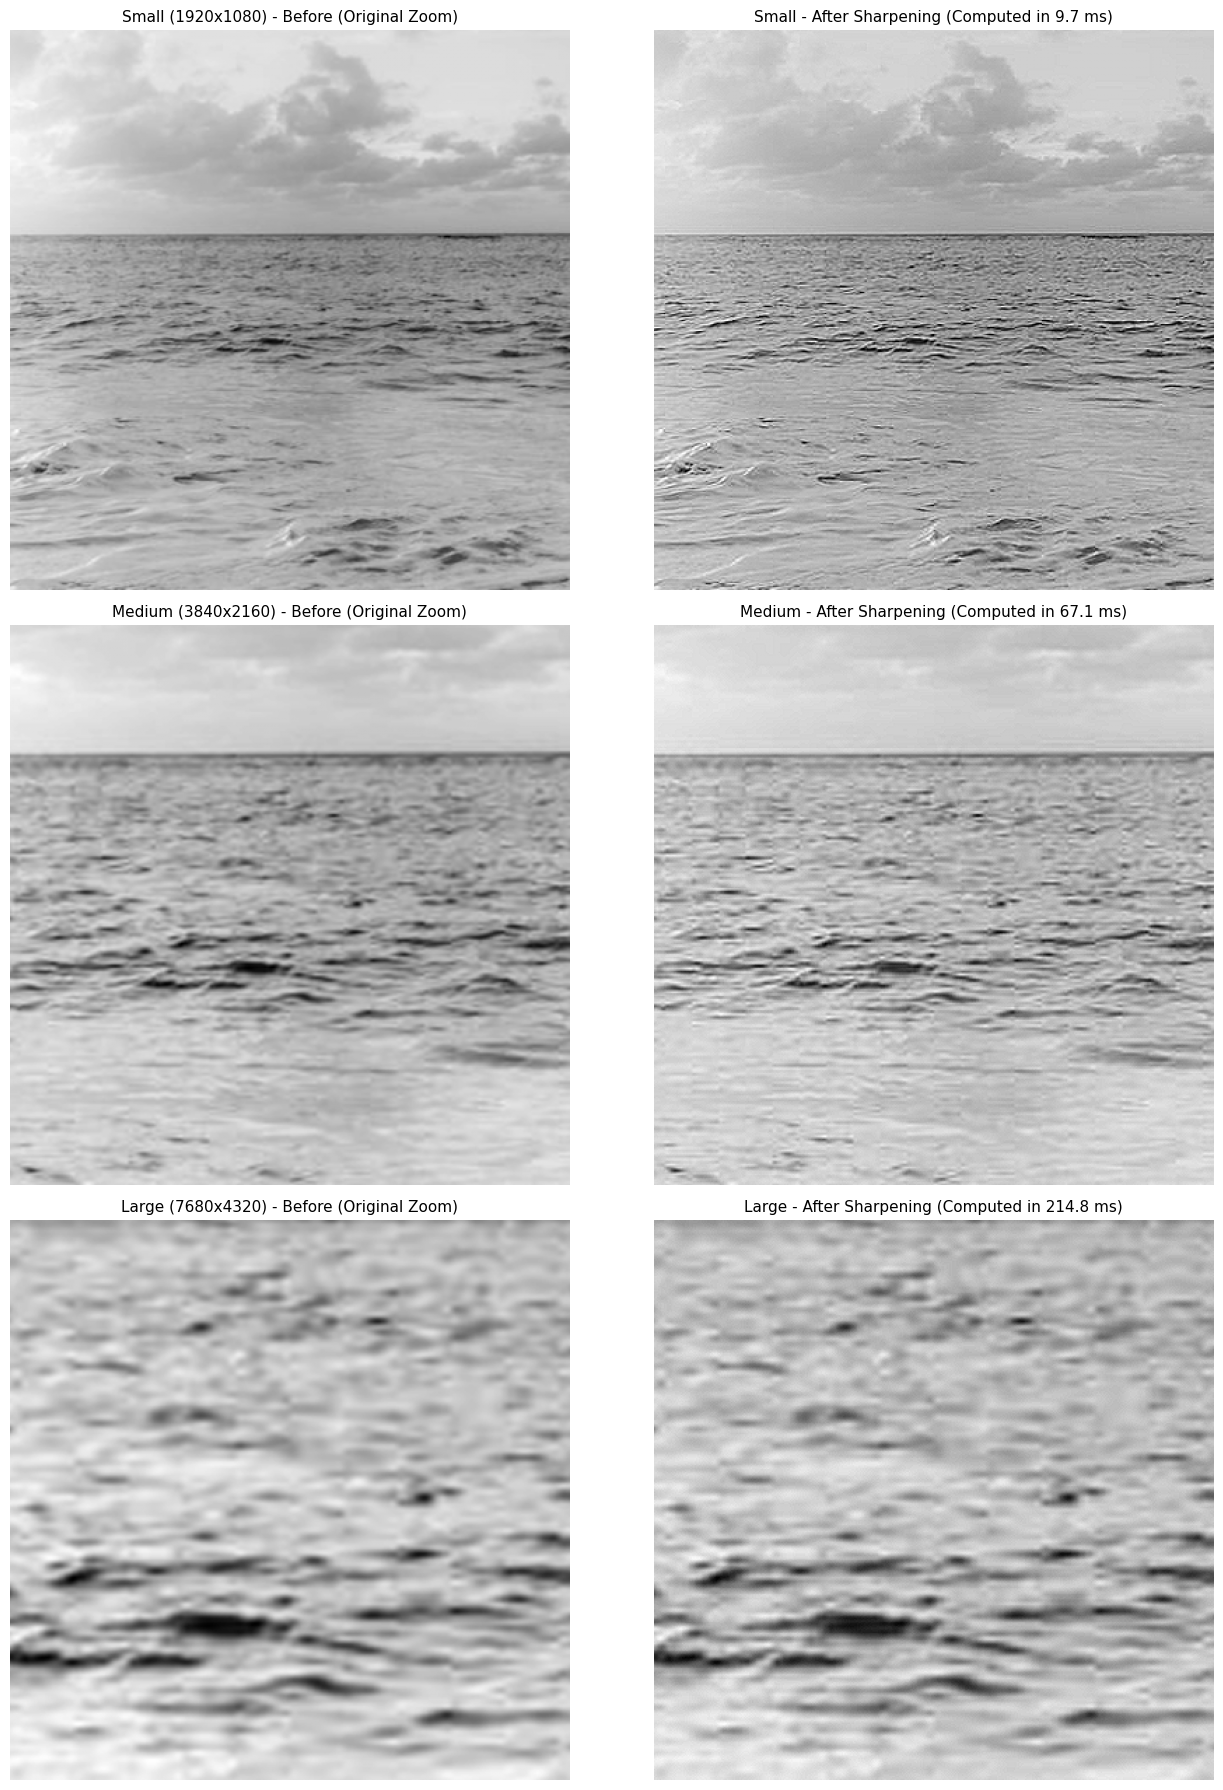

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(14, 18))
plt.subplots_adjust(hspace=0.25)

for idx, (category, w, h, in_file, out_file) in enumerate(configs):
    # Load raw buffers
    img_before = np.fromfile(in_file, dtype=np.uint8).reshape((h, w))
    img_after = np.fromfile(out_file, dtype=np.uint8).reshape((h, w))

    # Extract a centered 400x400 zoom region to highlight edge sharpening clearly
    cy, cx = h // 2, w // 2
    crop_before = img_before[cy - 200:cy + 200, cx - 200:cx + 200]
    crop_after = img_after[cy - 200:cy + 200, cx - 200:cx + 200]

    # Plot Before
    axes[idx, 0].imshow(crop_before, cmap='gray')
    axes[idx, 0].set_title(f"{category} ({w}x{h}) - Before (Original Zoom)", fontsize=11)
    axes[idx, 0].axis('off')

    # Plot After
    ms = benchmark_results.get(category, 0.0)
    axes[idx, 1].imshow(crop_after, cmap='gray')
    axes[idx, 1].set_title(f"{category} - After Sharpening (Computed in {ms:.1f} ms)", fontsize=11)
    axes[idx, 1].axis('off')

plt.tight_layout()
plt.show()

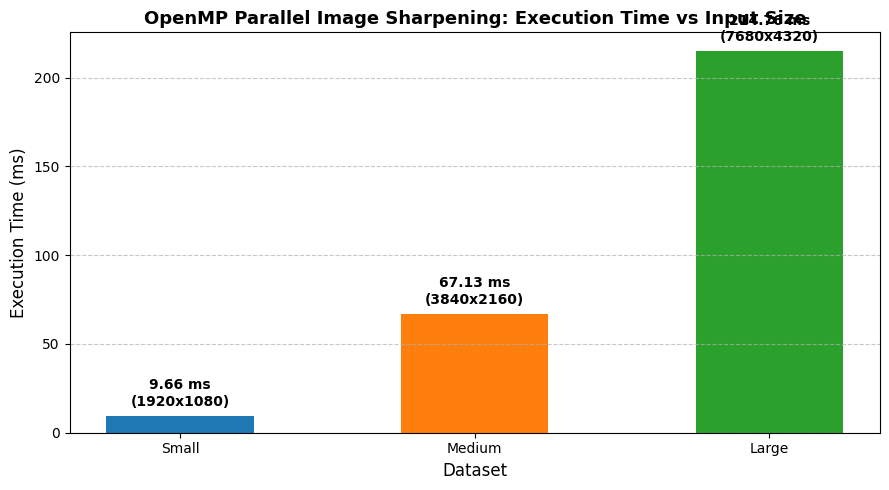

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Performance Bar Chart
labels = list(benchmark_results.keys())
times = list(benchmark_results.values())
resolutions = ["1920x1080", "3840x2160", "7680x4320"]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(labels, times, color=['#1f77b4', '#ff7f0e', '#2ca02c'], width=0.5)

ax.set_ylabel('Execution Time (ms)', fontsize=12)
ax.set_title('OpenMP Parallel Image Sharpening: Execution Time vs Input Size', fontsize=13, fontweight='bold')
ax.set_xlabel('Dataset', fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.7)

for bar, res in zip(bars, resolutions):
    height = bar.get_height()
    ax.annotate(f'{height:.2f} ms\n({res})',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

##Hardware Environment Check



In [ ]:
import psutil
import subprocess

# --- RAM ---
ram = psutil.virtual_memory()
print(f"Total RAM: {ram.total / (1024**3):.2f} GB")
print(f"Available RAM: {ram.available / (1024**3):.2f} GB")

# --- CPU ---
print(f"CPU Cores (Logical): {psutil.cpu_count(logical=True)}")
print(f"CPU Cores (Physical): {psutil.cpu_count(logical=False)}")

# --- GPU ---
try:
    gpu_info = subprocess.check_output(
        "nvidia-smi --query-gpu=name,memory.total,memory.free --format=csv",
        shell=True
    ).decode('utf-8').strip().split('\n')
    print("\nGPU Status:")
    for line in gpu_info:
        print(f"  {line}")
except Exception:
    print("\nGPU Status: No GPU allocated. (Check Runtime -> Change runtime type)")

Total RAM: 12.67 GB
Available RAM: 11.39 GB
CPU Cores (Logical): 2
CPU Cores (Physical): 1

GPU Status: No GPU allocated. (Check Runtime -> Change runtime type)


##B.1 Profiling CPU Version

In [ ]:
%%bash
# Compile binary with profiling flags enabled for gprof
g++ -O3 -pg -fopenmp sharpen_omp.cpp -o sharpen_omp_gprof

# Run the gprof-instrumented binary to produce gmon.out using the large dataset
./sharpen_omp_gprof input_large.bin out_gprof.bin 7680 4320 > /dev/null

echo "=== B.1 — CPU Hotspots & Call Counts (gprof) ==="
gprof ./sharpen_omp_gprof gmon.out | head -25

echo -e "\n=== B.1 — CPU Cycles & Cache Performance (perf stat) ==="
perf stat -e cycles,instructions,cache-references,cache-misses ./sharpen_omp input_large.bin out_perf_stat.bin 7680 4320

=== B.1 — CPU Hotspots & Call Counts (gprof) ===
Flat profile:

Each sample counts as 0.01 seconds.
  %   cumulative   self              self     total           
 time   seconds   seconds    calls  Ts/call  Ts/call  name    
100.00      0.29     0.29                             frame_dummy
  0.00      0.29     0.00        4     0.00     0.00  std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >::basic_string<std::allocator<char> >(char const*, std::allocator<char> const&)
  0.00      0.29     0.00        2     0.00     0.00  int __gnu_cxx::__stoa<long, int, char, int>(long (*)(char const*, char**, int), char const*, char const*, unsigned long*, int)
  0.00      0.29     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::vector(unsigned long, std::allocator<unsigned char> const&)
  0.00      0.29     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::~vector()

 %         the 


  You may need to install the following packages for this specific kernel:
    linux-tools-6.6.122+-6.6.122+
    linux-cloud-tools-6.6.122+-6.6.122+

  You may also want to install one of the following packages to keep up to date:
    linux-tools-6.6.122+
    linux-cloud-tools-6.6.122+


CalledProcessError: Command 'b'# Compile binary with profiling flags enabled for gprof\ng++ -O3 -pg -fopenmp sharpen_omp.cpp -o sharpen_omp_gprof\n\n# Run the gprof-instrumented binary to produce gmon.out using the large dataset\n./sharpen_omp_gprof input_large.bin out_gprof.bin 7680 4320 > /dev/null\n\necho "=== B.1 \xe2\x80\x94 CPU Hotspots & Call Counts (gprof) ==="\ngprof ./sharpen_omp_gprof gmon.out | head -25\n\necho -e "\\n=== B.1 \xe2\x80\x94 CPU Cycles & Cache Performance (perf stat) ==="\nperf stat -e cycles,instructions,cache-references,cache-misses ./sharpen_omp input_large.bin out_perf_stat.bin 7680 4320\n'' returned non-zero exit status 2.

In [ ]:
%%bash
# 1. Compile with -pg
g++ -O3 -fopenmp -pg sharpen_omp.cpp -o sharpen_omp

# 2. Set OMP_NUM_THREADS and run with the Large dataset on 4 threads
export OMP_NUM_THREADS=4
./sharpen_omp input_large.bin out_gprof.bin 7680 4320 4

# 3. Generate the gprof report
gprof sharpen_omp gmon.out > gprof_omp_report.txt

# 4. Extract Flat Profile
echo "=== FLAT PROFILE ==="
sed -n '/Flat profile:/,/Call graph/p' gprof_omp_report.txt

echo -e "\n=== CALL GRAPH ==="
grep -A50 "^Call graph" gprof_omp_report.txt | head -60

239.636=== FLAT PROFILE ===
Flat profile:

Each sample counts as 0.01 seconds.
  %   cumulative   self              self     total           
 time   seconds   seconds    calls  Ts/call  Ts/call  name    
100.00      0.23     0.23                             frame_dummy
  0.00      0.23     0.00        5     0.00     0.00  std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >::basic_string<std::allocator<char> >(char const*, std::allocator<char> const&)
  0.00      0.23     0.00        3     0.00     0.00  int __gnu_cxx::__stoa<long, int, char, int>(long (*)(char const*, char**, int), char const*, char const*, unsigned long*, int)
  0.00      0.23     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::vector(unsigned long, std::allocator<unsigned char> const&)
  0.00      0.23     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::~vector()

 %         the percentage of the tot

In [ ]:
!g++ -O0 -g -pg -fopenmp sharpen_omp.cpp -o sharpen_omp_gprof

In [ ]:
%env OMP_NUM_THREADS=4

env: OMP_NUM_THREADS=4


In [ ]:
!./sharpen_omp_gprof input_large.bin out_gprof.bin 7680 4320 4

5069.67

In [ ]:
!grep -A30 "Flat profile:" gprof_omp_report.txt

Flat profile:

Each sample counts as 0.01 seconds.
  %   cumulative   self              self     total           
 time   seconds   seconds    calls  Ts/call  Ts/call  name    
100.00      0.23     0.23                             frame_dummy
  0.00      0.23     0.00        5     0.00     0.00  std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >::basic_string<std::allocator<char> >(char const*, std::allocator<char> const&)
  0.00      0.23     0.00        3     0.00     0.00  int __gnu_cxx::__stoa<long, int, char, int>(long (*)(char const*, char**, int), char const*, char const*, unsigned long*, int)
  0.00      0.23     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::vector(unsigned long, std::allocator<unsigned char> const&)
  0.00      0.23     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::~vector()

 %         the percentage of the total running time of the
time 

In [ ]:
!grep -A80 "Call graph" gprof_omp_report.txt

		     Call graph (explanation follows)


granularity: each sample hit covers 4 byte(s) for 4.35% of 0.23 seconds

index % time    self  children    called     name
                                                 <spontaneous>
[1]    100.0    0.23    0.00                 frame_dummy [1]
-----------------------------------------------
                0.00    0.00       5/5           main [6]
[8]      0.0    0.00    0.00       5         std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >::basic_string<std::allocator<char> >(char const*, std::allocator<char> const&) [8]
-----------------------------------------------
                0.00    0.00       3/3           main [6]
[9]      0.0    0.00    0.00       3         int __gnu_cxx::__stoa<long, int, char, int>(long (*)(char const*, char**, int), char const*, char const*, unsigned long*, int) [9]
-----------------------------------------------
                0.00    0.00       2/2           main [6]
[10]     

In [ ]:
!grep -E "sharpen|omp|GOMP|_omp_fn" gprof_omp_report.txt | head -50

In [ ]:
!rm -f gmon.out

In [ ]:
!g++ -O3 -fopenmp -pg sharpen_omp.cpp -o sharpen_omp

In [ ]:
%env OMP_NUM_THREADS=4

env: OMP_NUM_THREADS=4


In [ ]:
!./sharpen_omp input_large.bin out_gprof.bin 7680 4320 4

153.793

In [ ]:
!ls -lh gmon.out

-rw-r--r-- 1 root root 6.6K Oct  6 20:13 gmon.out


In [ ]:
!gprof sharpen_omp gmon.out

Flat profile:

Each sample counts as 0.01 seconds.
  %   cumulative   self              self     total           
 time   seconds   seconds    calls  Ts/call  Ts/call  name    
100.00      0.30     0.30                             frame_dummy
  0.00      0.30     0.00        5     0.00     0.00  std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >::basic_string<std::allocator<char> >(char const*, std::allocator<char> const&)
  0.00      0.30     0.00        3     0.00     0.00  int __gnu_cxx::__stoa<long, int, char, int>(long (*)(char const*, char**, int), char const*, char const*, unsigned long*, int)
  0.00      0.30     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::vector(unsigned long, std::allocator<unsigned char> const&)
  0.00      0.30     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::~vector()

 %         the percentage of the total running time of the
time 

In [ ]:
!sed -n '/Flat profile:/,/Call graph/p' gprof_omp_report.txt

Flat profile:

Each sample counts as 0.01 seconds.
  %   cumulative   self              self     total           
 time   seconds   seconds    calls  Ts/call  Ts/call  name    
100.00      0.23     0.23                             frame_dummy
  0.00      0.23     0.00        5     0.00     0.00  std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >::basic_string<std::allocator<char> >(char const*, std::allocator<char> const&)
  0.00      0.23     0.00        3     0.00     0.00  int __gnu_cxx::__stoa<long, int, char, int>(long (*)(char const*, char**, int), char const*, char const*, unsigned long*, int)
  0.00      0.23     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::vector(unsigned long, std::allocator<unsigned char> const&)
  0.00      0.23     0.00        2     0.00     0.00  std::vector<unsigned char, std::allocator<unsigned char> >::~vector()

 %         the percentage of the total running time of the
time 

In [ ]:
%%bash
BIN=./sharpen_omp
SRC=sharpen_omp.cpp
FLAGS="-O3 -fopenmp"
ARGS="input_large.bin out_perf.bin 7680 4320"

echo "=== Installing perf ==="
apt-get -qq update > /dev/null 2>&1
apt-get -qq install -y linux-tools-common linux-tools-generic > /dev/null 2>&1
PERF=$(ls /usr/lib/linux-tools/*/perf 2>/dev/null | head -1)
[ -z "$PERF" ] && PERF=$(command -v perf)

if [ -n "$PERF" ]; then
  echo "=== B.1 attempt: perf record hotspots ==="
  $PERF record -e cpu-clock -F 999 -g -o perf.data $BIN $ARGS 2>&1 | tail -5
  $PERF report -i perf.data --stdio --sort symbol 2>&1 | grep -v '^$' | head -40
fi


=== Installing perf ===
=== B.1 attempt: perf record hotspots ===
Check /proc/kallsyms permission or run as root.
get_bpf_prog_info_linear: mismatch in array 0x59ed5b2a34d8 vs 0
Couldn't synthesize bpf events.
154.973[ perf record: Woken up 1 times to write data ]
[ perf record: Captured and wrote 0.031 MB perf.data (379 samples) ]
Kernel address maps (/proc/{kallsyms,modules}) were restricted.
Check /proc/sys/kernel/kptr_restrict before running 'perf record'.
As no suitable kallsyms nor vmlinux was found, kernel samples
can't be resolved.
Samples in kernel modules can't be resolved as well.
# To display the perf.data header info, please use --header/--header-only options.
#
#
# Total Lost Samples: 0
#
# Samples: 379  of event 'cpu-clock'
# Event count (approx.): 379379379
#
# Children      Self  Symbol                                                                              IPC   [IPC Coverage]
# ........  ........  .................................................................

In [ ]:
%%bash
echo "=================================================="
echo "STEP 2 — INSPECT THE BINARY SYMBOLS"
echo "=================================================="
nm -C ./sharpen_omp | grep -E "sharpen|omp|GOMP" || true
echo ""
objdump -t -C ./sharpen_omp | grep -E "sharpen|omp|GOMP" || true

echo -e "\n=================================================="
echo "STEP 3 & 4 — INVESTIGATE PERF SOFTWARE SAMPLING"
echo "=================================================="
perf --version || true
perf list | grep -E "clock|software" | head -n 10 || true

# Record using software event cpu-clock
perf record -e cpu-clock -F 999 -g -o perf_omp_4.data ./sharpen_omp input_large.bin out_perf_4.bin 7680 4320 4

# Generate a clean text report of the symbols
perf report -i perf_omp_4.data --stdio --sort symbol | head -40

echo -e "\n=================================================="
echo "STEP 5 — INVESTIGATE GPROF SYMBOLS"
echo "=================================================="
nm -C ./sharpen_omp_gprof | grep -E "sharpen|omp|GOMP" || true

echo -e "\n=================================================="
echo "STEP 6 — CPU CYCLES AND CACHE MISSES"
echo "=================================================="
perf stat -e cycles,instructions,cache-references,cache-misses ./sharpen_omp input_large.bin out_perf_stat.bin 7680 4320 4 2>&1 || true

STEP 2 — INSPECT THE BINARY SYMBOLS
0000000000006274 b completed.0
                 U GOMP_parallel@GOMP_4.0
                 U omp_get_num_threads@OMP_1.0
                 U omp_get_thread_num@OMP_1.0
                 U omp_get_wtime@OMP_2.0
                 U omp_set_num_threads@OMP_1.0
0000000000002e40 T sharpen_omp(unsigned char const*, unsigned char*, int, int)
00000000000029e0 t sharpen_omp(unsigned char const*, unsigned char*, int, int) [clone ._omp_fn.0]

./sharpen_omp:     file format elf64-x86-64
0000000000000000 l    df *ABS*	0000000000000000              sharpen_omp.cpp
00000000000029e0 l     F .text	0000000000000456              sharpen_omp(unsigned char const*, unsigned char*, int, int) [clone ._omp_fn.0]
0000000000006274 l     O .bss	0000000000000001              completed.0
0000000000002e40 g     F .text	0000000000000059              sharpen_omp(unsigned char const*, unsigned char*, int, int)
0000000000000000       F *UND*	0000000000000000              omp_set_num_threa


  You may need to install the following packages for this specific kernel:
    linux-tools-6.6.122+-6.6.122+
    linux-cloud-tools-6.6.122+-6.6.122+

  You may also want to install one of the following packages to keep up to date:
    linux-tools-6.6.122+
    linux-cloud-tools-6.6.122+

  You may need to install the following packages for this specific kernel:
    linux-tools-6.6.122+-6.6.122+
    linux-cloud-tools-6.6.122+-6.6.122+

  You may also want to install one of the following packages to keep up to date:
    linux-tools-6.6.122+
    linux-cloud-tools-6.6.122+

  You may need to install the following packages for this specific kernel:
    linux-tools-6.6.122+-6.6.122+
    linux-cloud-tools-6.6.122+-6.6.122+

  You may also want to install one of the following packages to keep up to date:
    linux-tools-6.6.122+
    linux-cloud-tools-6.6.122+

  You may need to install the following packages for this specific kernel:
    linux-tools-6.6.122+-6.6.122+
    linux-cloud-tools-6.6.